# <div style="border-radius:12px; border: #1E3A8A solid 2px; background-color:#F0F4F8; padding: 20px; text-align: center;">
<h1 style="color:#1E3A8A; font-family:'Segoe UI', Tahoma, Geneva, Verdana, sans-serif; font-weight: bold; margin-bottom: 5px;">
DEPI Graduation Project - Machine Learning & MLOps Pipeline
</h1>
<h2 style="color:#2563EB; font-family:'Segoe UI', Tahoma, Geneva, Verdana, sans-serif; font-style: italic; margin-top: 0px;">
Comprehensive Exploratory Data Analysis (EDA) & Churn Driver Investigation
</h2>
<p style="font-size: 110%; color: #4B5563;">
<b>Dataset:</b> Telco Customer Churn | <b>Focus:</b> Customer Retention & Feature Drift Monitoring for MLOps Simulator
</p>
</div>

---

## 📌 Executive Summary & Project Context

In this project, we are developing an end-to-end **Customer Churn Prediction and Continuous Retraining System (MLOps)**.
The business goal is twofold:
1. **Understand Customer Attrition:** Uncover the behavioral, demographic, and contractual patterns causing telecom customers to leave.
2. **Drive the MLOps Drift Simulator:** Identify the most predictive drivers of churn (e.g., Contract type, Tenure, Monthly Charges, Tech Support) so that changes in their underlying distribution across incoming weekly live batches (`data/live/features/week_*.csv`) trigger data drift detection and prompt automated model retraining (`simulate_retraining.py`).

### 🎯 Research Questions Driving This Investigation:
- **Univariate Analysis:**
  - What is the overall churn rate (class imbalance)?
  - How are customer tenures distributed across the customer lifecycle?
  - What does the distribution of monthly billing and total charges look like?
  - What are the most popular contract types and internet service tiers?
- **Bivariate Analysis (Customer Churn Drivers):**
  - How does customer tenure influence churn probability?
  - Why are Month-to-Month contracts associated with the highest churn rates?
  - Does paying via Electronic Check indicate higher churn risk compared to automatic payments?
  - How do value-added services (Tech Support, Online Security) act as retention anchors?
- **Multivariate Analysis & MLOps Relevance:**
  - What are the correlation dynamics between numerical attributes and churn?
  - How does contract type interact with tenure and monthly spend?
  - Which key features must be strictly tracked for **Feature Drift** in production to maintain model reliability?



# 1. ⚙️ Environment Setup & Library Imports


In [17]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import warnings

# Suppress minor warnings for clean presentation
warnings.filterwarnings('ignore')

# Set aesthetic styling
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['font.size'] = 11

# Set display options
pd.set_option('display.max_columns', 50)
pd.set_option('display.width', 1000)

print("✅ Libraries successfully imported.")


✅ Libraries successfully imported.


# 2. 📂 Data Acquisition & Initial Inspection

We load the raw Telco dataset (`Telco_customer_churn.xlsx`) or fallback to the processed dataset depending on execution directory context.



In [18]:
# Define possible file locations for flexibility across repository root and notebooks directory
raw_path_root = Path("data/raw/Telco_customer_churn.xlsx")
raw_path_parent = Path("../data/raw/Telco_customer_churn.xlsx")
csv_fallback_root = Path("data/processed/Telco_customer_churn_cleaned.csv")
csv_fallback_parent = Path("../data/processed/Telco_customer_churn_cleaned.csv")

if raw_path_root.exists():
    df_raw = pd.read_excel(raw_path_root)
    print(f"Loaded raw dataset from: {raw_path_root}")
elif raw_path_parent.exists():
    df_raw = pd.read_excel(raw_path_parent)
    print(f"Loaded raw dataset from: {raw_path_parent}")
elif csv_fallback_root.exists():
    df_raw = pd.read_csv(csv_fallback_root)
    print(f"Loaded fallback dataset from: {csv_fallback_root}")
elif csv_fallback_parent.exists():
    df_raw = pd.read_csv(csv_fallback_parent)
    print(f"Loaded fallback dataset from: {csv_fallback_parent}")
else:
    raise FileNotFoundError("Could not locate Telco customer churn dataset in data/raw or data/processed.")

print("Dataset Shape (Rows, Columns):", df_raw.shape)
df_raw.head(5)


Loaded raw dataset from: ..\data\raw\Telco_customer_churn.xlsx
Dataset Shape (Rows, Columns): (7043, 33)


,CustomerID,Count,Country,State,City,Zip Code,Lat Long,Latitude,Longitude,Gender,Senior Citizen,Partner,Dependents,Tenure Months,Phone Service,Multiple Lines,Internet Service,Online Security,Online Backup,Device Protection,Tech Support,Streaming TV,Streaming Movies,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges,Churn Label,Churn Value,Churn Score,CLTV,Churn Reason
0,3668-QPYBK,1,United States,California,Los Angeles,90003,"33.964131, -118.272783",33.964131,-118.272783,Male,No,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,1,86,3239,Competitor made better offer
1,9237-HQITU,1,United States,California,Los Angeles,90005,"34.059281, -118.30742",34.059281,-118.307420,Female,No,No,Yes,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,1,67,2701,Moved
2,9305-CDSKC,1,United States,California,Los Angeles,90006,"34.048013, -118.293953",34.048013,-118.293953,Female,No,No,Yes,8,Yes,Yes,Fiber optic,No,No,Yes,No,Yes,Yes,Month-to-month,Yes,Electronic check,99.65,820.5,Yes,1,86,5372,Moved
3,7892-POOKP,1,United States,California,Los Angeles,90010,"34.062125, -118.315709",34.062125,-118.315709,Female,No,Yes,Yes,28,Yes,Yes,Fiber optic,No,No,Yes,Yes,Yes,Yes,Month-to-month,Yes,Electronic check,104.80,3046.05,Yes,1,84,5003,Moved
4,0280-XJGEX,1,United States,California,Los Angeles,90015,"34.039224, -118.266293",34.039224,-118.266293,Male,No,No,Yes,49,Yes,Yes,Fiber optic,No,Yes,Yes,No,Yes,Yes,Month-to-month,Yes,Bank transfer (automatic),103.70,5036.3,Yes,1,89,5340,Competitor had better devices


# 3. 🔍 Data Profiling, Types & Quality Auditing

Here we inspect data types, missing values, duplicates, and unique cardinalities.



In [19]:
# High-level data types and unique counts overview table (similar to our baseline EDA template)
dtypes_df = pd.DataFrame({
    "Data Type": df_raw.dtypes,
    "Unique Values": df_raw.nunique(),
    "Null Count": df_raw.isnull().sum(),
    "Null Percentage (%)": (df_raw.isnull().sum() / len(df_raw)) * 100
})
dtypes_df.T


,CustomerID,Count,Country,State,City,Zip Code,Lat Long,Latitude,Longitude,Gender,Senior Citizen,Partner,Dependents,Tenure Months,Phone Service,Multiple Lines,Internet Service,Online Security,Online Backup,Device Protection,Tech Support,Streaming TV,Streaming Movies,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges,Churn Label,Churn Value,Churn Score,CLTV,Churn Reason
Data Type,object,int64,object,object,object,int64,object,float64,float64,object,object,object,object,int64,object,object,object,object,object,object,object,object,object,object,object,object,float64,object,object,int64,int64,int64,object
Unique Values,7043,1,1,1,1129,1652,1652,1652,1651,2,2,2,2,73,2,3,3,3,3,3,3,3,3,3,2,4,1585,6531,2,2,85,3438,20
Null Count,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,5174
Null Percentage (%),0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,73.463013


In [20]:
# Summary statistics for numeric features
df_raw.describe().T


,count,mean,std,min,25%,50%,75%,max
Count,7043.0,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000
Zip Code,7043.0,93521.964646,1865.794555,90001.000000,92102.000000,93552.000000,95351.000000,96161.000000
Latitude,7043.0,36.282441,2.455723,32.555828,34.030915,36.391777,38.224869,41.962127
Longitude,7043.0,-119.798880,2.157889,-124.301372,-121.815412,-119.730885,-118.043237,-114.192901
Tenure Months,7043.0,32.371149,24.559481,0.000000,9.000000,29.000000,55.000000,72.000000
Monthly Charges,7043.0,64.761692,30.090047,18.250000,35.500000,70.350000,89.850000,118.750000
Churn Value,7043.0,0.265370,0.441561,0.000000,0.000000,0.000000,1.000000,1.000000
Churn Score,7043.0,58.699418,21.525131,5.000000,40.000000,61.000000,75.000000,100.000000
CLTV,7043.0,4400.295755,1183.057152,2003.000000,3469.000000,4527.000000,5380.500000,6500.000000


In [21]:
# Check duplicate customer identifiers and duplicate rows
if "CustomerID" in df_raw.columns:
    print(f"Duplicate Customer IDs: {df_raw['CustomerID'].duplicated().sum()}")
print(f"Duplicate Complete Rows: {df_raw.duplicated().sum()}")


Duplicate Customer IDs: 0
Duplicate Complete Rows: 0


# 4. 🧹 Data Preprocessing for Analysis

Key Cleaning Decisions:
1. **Total Charges Conversion:** Whitespace values in `Total Charges` are converted to numerical NaN and imputed with `0`, corresponding to brand-new customers with `Tenure Months == 0`.
2. **Feature Pruning:** Remove non-predictive operational metadata (e.g. `CustomerID`, `Count`, `Country`, `State`, `Lat Long`, `Zip Code`) and target leakage columns (`Churn Reason`, `Churn Score`).
3. **Target Standardisation:** Ensure `Churn Value` (1 for Churned, 0 for Retained) and `Churn Label` are clearly aligned for informative plotting.



In [22]:
df = df_raw.copy()

# 1. Total Charges handling
if "Total Charges" in df.columns:
    df["Total Charges"] = pd.to_numeric(df["Total Charges"], errors="coerce")
    null_tc = df["Total Charges"].isna().sum()
    print(f"Found {null_tc} records with non-numeric Total Charges. Imputing with 0.0 (new customers).")
    df["Total Charges"] = df["Total Charges"].fillna(0.0)

# 2. Standardize column names if needed
if "Churn Value" in df.columns and "Churn" not in df.columns:
    df["Churn"] = df["Churn Value"].map({1: "Yes", 0: "No"})

# 3. Create tenure groups for enhanced cohort analysis
if "Tenure Months" in df.columns:
    df["Tenure Cohort"] = pd.cut(
        df["Tenure Months"],
        bins=[-1, 12, 24, 48, 60, 72],
        labels=["0-1 Year", "1-2 Years", "2-4 Years", "4-5 Years", "5+ Years"]
    )

print("Dataset prepared successfully for EDA. Active rows:", len(df))


Found 11 records with non-numeric Total Charges. Imputing with 0.0 (new customers).
Dataset prepared successfully for EDA. Active rows: 7043


# 5. 📊 Univariate Exploration

Let's study the distribution and characteristics of individual variables.



### 5.1 What is the Overall Customer Churn Distribution (Class Imbalance)?


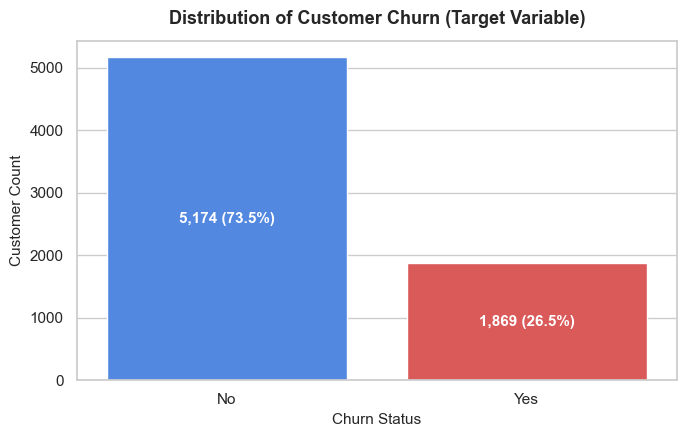

In [23]:
plt.figure(figsize=(7, 4.5))
churn_counts = df['Churn'].value_counts()
colors = ['#3B82F6', '#EF4444']

ax = sns.barplot(x=churn_counts.index, y=churn_counts.values, palette=colors)
plt.title("Distribution of Customer Churn (Target Variable)", fontsize=13, fontweight='bold', pad=12)
plt.xlabel("Churn Status", fontsize=11)
plt.ylabel("Customer Count", fontsize=11)

# Annotate counts and percentages
total = len(df)
for p in ax.patches:
    height = p.get_height()
    pct = (height / total) * 100
    ax.annotate(f"{int(height):,} ({pct:.1f}%)",
                (p.get_x() + p.get_width() / 2., height / 2),
                ha='center', va='center', color='white', fontweight='bold', fontsize=11)

plt.tight_layout()
plt.show()


> **💡 Insight:**
> - Roughly **26.5%** of customers have churned (`Yes`), while **73.5%** remain retained (`No`).
> - This moderate **class imbalance (~1:3)** indicates that evaluation metrics like **PR-AUC, ROC-AUC, and Recall** will be critical during automated model retraining rather than raw Accuracy alone.



### 5.2 How is Customer Tenure Distributed Across the Base?


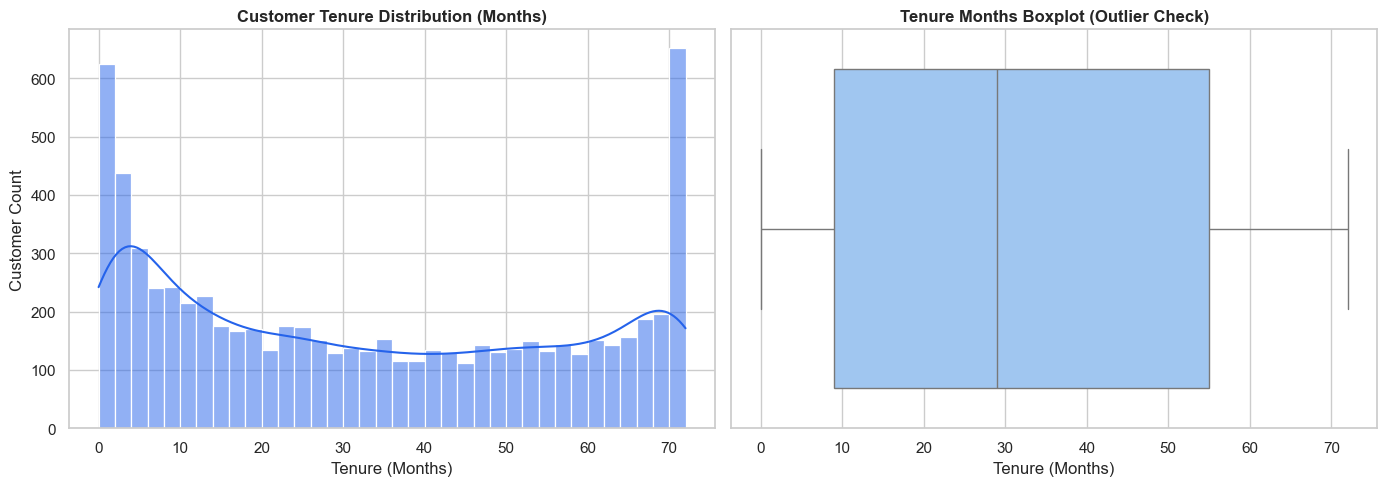

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Histogram / KDE
sns.histplot(df["Tenure Months"], kde=True, bins=36, color="#2563EB", ax=axes[0])
axes[0].set_title("Customer Tenure Distribution (Months)", fontweight='bold')
axes[0].set_xlabel("Tenure (Months)")
axes[0].set_ylabel("Customer Count")

# Boxplot for Outlier Inspection
sns.boxplot(x=df["Tenure Months"], color="#93C5FD", ax=axes[1])
axes[1].set_title("Tenure Months Boxplot (Outlier Check)", fontweight='bold')
axes[1].set_xlabel("Tenure (Months)")

plt.tight_layout()
plt.show()


> **💡 Insight:**
> - The tenure distribution exhibits a **bimodal distribution**: a large spike of brand-new customers ($0-5$ months) and another substantial cluster of long-standing loyal customers ($65-72$ months).
> - There are **no extreme outliers**; tenure strictly adheres to the $0$ to $72$ months business bounds.



### 5.3 What is the Distribution of Monthly Charges and Total Lifetime Charges?


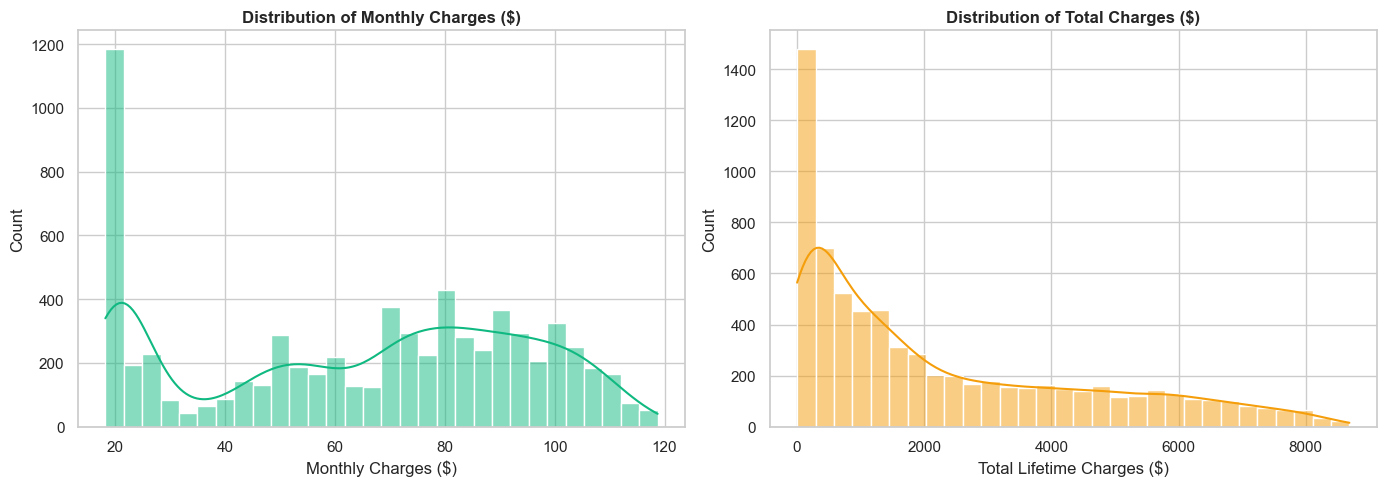

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(df["Monthly Charges"], kde=True, bins=30, color="#10B981", ax=axes[0])
axes[0].set_title("Distribution of Monthly Charges ($)", fontweight='bold')
axes[0].set_xlabel("Monthly Charges ($)")
axes[0].set_ylabel("Count")

sns.histplot(df["Total Charges"], kde=True, bins=30, color="#F59E0B", ax=axes[1])
axes[1].set_title("Distribution of Total Charges ($)", fontweight='bold')
axes[1].set_xlabel("Total Lifetime Charges ($)")
axes[1].set_ylabel("Count")

plt.tight_layout()
plt.show()


> **💡 Insight:**
> - **Monthly Charges:** High density around \$20 (representing basic telephone-only packages) and another peak between \$70 - \$90 (fiber-optic internet packages with add-on streaming).
> - **Total Charges:** Strongly right-skewed as expected, since total billing accumulates proportionally to tenure length.



### 5.4 What are the Proportions of Contract Types & Internet Service Modes?


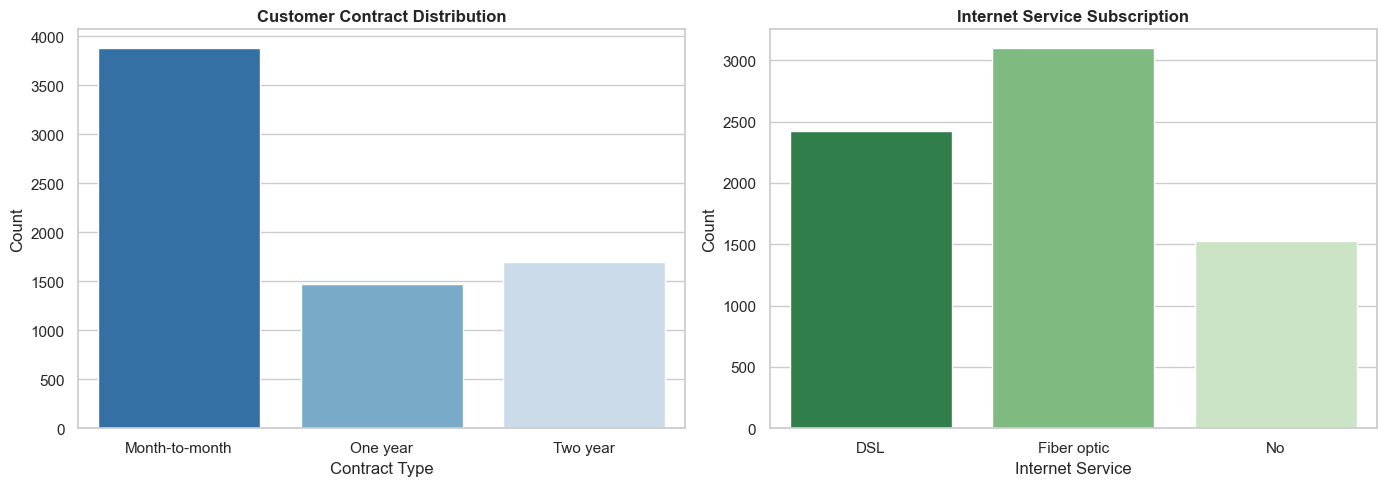

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Contract distribution
sns.countplot(data=df, x="Contract", palette="Blues_r", order=["Month-to-month", "One year", "Two year"], ax=axes[0])
axes[0].set_title("Customer Contract Distribution", fontweight='bold')
axes[0].set_xlabel("Contract Type")
axes[0].set_ylabel("Count")

# Internet Service distribution
sns.countplot(data=df, x="Internet Service", palette="Greens_r", ax=axes[1])
axes[1].set_title("Internet Service Subscription", fontweight='bold')
axes[1].set_xlabel("Internet Service")
axes[1].set_ylabel("Count")

plt.tight_layout()
plt.show()


> **💡 Insight:**
> - Over **55%** of subscribers hold flexible **Month-to-month** contracts, representing high mobility and high exposure to churn.
> - **Fiber optic** is the most adopted internet tier (~44%), followed by DSL (~34%) and No Internet (~21%).



# 6. 📈 Bivariate Exploration: Identifying Churn Drivers

In this section, we directly analyze how individual attributes influence the likelihood of churn.



### 6.1 How Does Tenure Influence Churn Behavior?


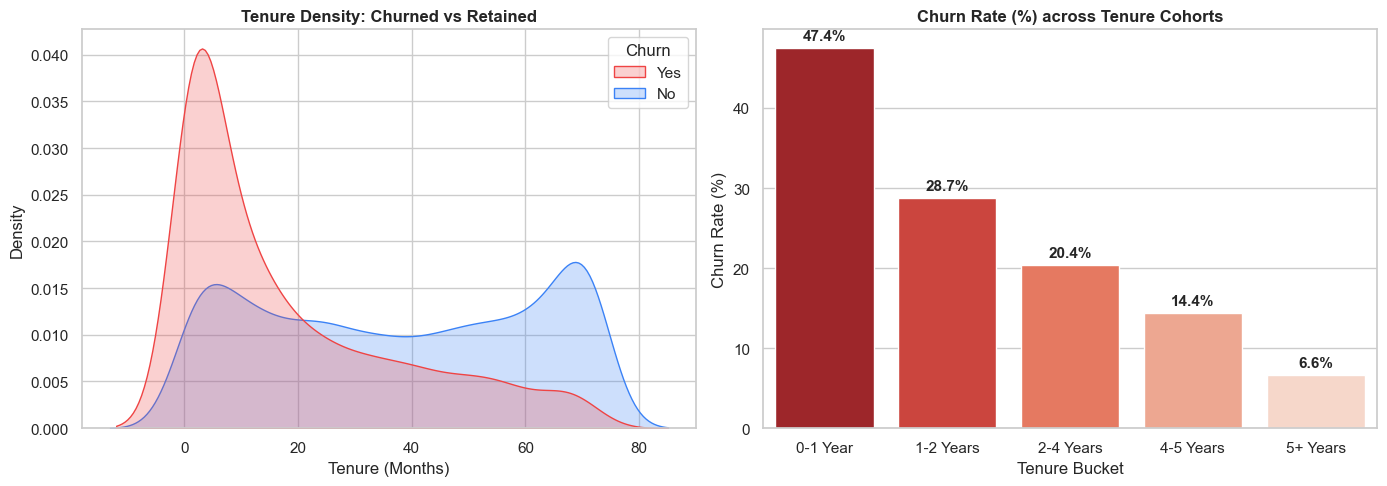

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# KDE Plot by Churn Status
sns.kdeplot(data=df, x="Tenure Months", hue="Churn", common_norm=False, fill=True, palette={"No": "#3B82F6", "Yes": "#EF4444"}, ax=axes[0])
axes[0].set_title("Tenure Density: Churned vs Retained", fontweight='bold')
axes[0].set_xlabel("Tenure (Months)")

# Churn rate across Tenure Cohorts
cohort_churn = df.groupby("Tenure Cohort")["Churn"].apply(lambda s: (s == "Yes").mean() * 100).reset_index()
sns.barplot(data=cohort_churn, x="Tenure Cohort", y="Churn", palette="Reds_r", ax=axes[1])
axes[1].set_title("Churn Rate (%) across Tenure Cohorts", fontweight='bold')
axes[1].set_xlabel("Tenure Bucket")
axes[1].set_ylabel("Churn Rate (%)")
for p in axes[1].patches:
    axes[1].annotate(f"{p.get_height():.1f}%", (p.get_x() + p.get_width() / 2., p.get_height() + 1), ha='center', fontweight='bold')

plt.tight_layout()
plt.show()


> **💡 Key Finding:**
> - Customers in their **first year (0-12 months)** suffer a staggering **~47% churn rate**.
> - As customer tenure increases past 2 years, churn falls below 20%, and drops to under 7% for customers with 5+ years of tenure.
> - **Retaining customers during the first 90–180 days is the single most critical business lever.**



### 6.2 What is the Impact of Contract Type on Churn Rate?


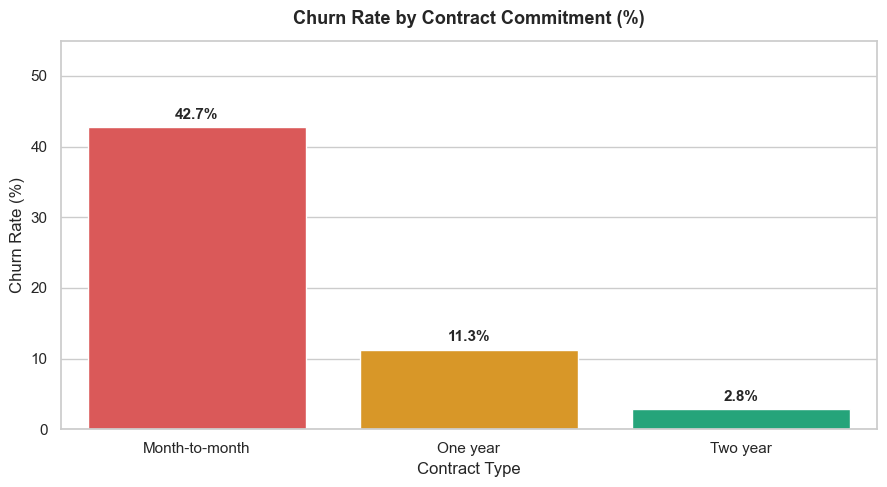

In [28]:
plt.figure(figsize=(9, 5))

contract_churn = df.groupby("Contract")["Churn"].apply(lambda s: (s == "Yes").mean() * 100).reindex(["Month-to-month", "One year", "Two year"])
ax = sns.barplot(x=contract_churn.index, y=contract_churn.values, palette=["#EF4444", "#F59E0B", "#10B981"])
plt.title("Churn Rate by Contract Commitment (%)", fontsize=13, fontweight='bold', pad=12)
plt.ylabel("Churn Rate (%)")
plt.xlabel("Contract Type")
plt.ylim(0, 55)

for p in ax.patches:
    ax.annotate(f"{p.get_height():.1f}%",
                (p.get_x() + p.get_width() / 2., p.get_height() + 1.2),
                ha='center', fontweight='bold')

plt.tight_layout()
plt.show()


> **💡 Key Finding:**
> - Customers on **Month-to-month contracts** experience a **42.7% churn rate**.
> - In stark contrast, commitment to a **One-year (11.3%)** or **Two-year (2.8%)** contract slashes churn drastically.
> - Contract type is arguably the **strongest deterministic predictor** in the dataset.



### 6.3 Do Monthly Charges & Internet Service Types Drive Churn?


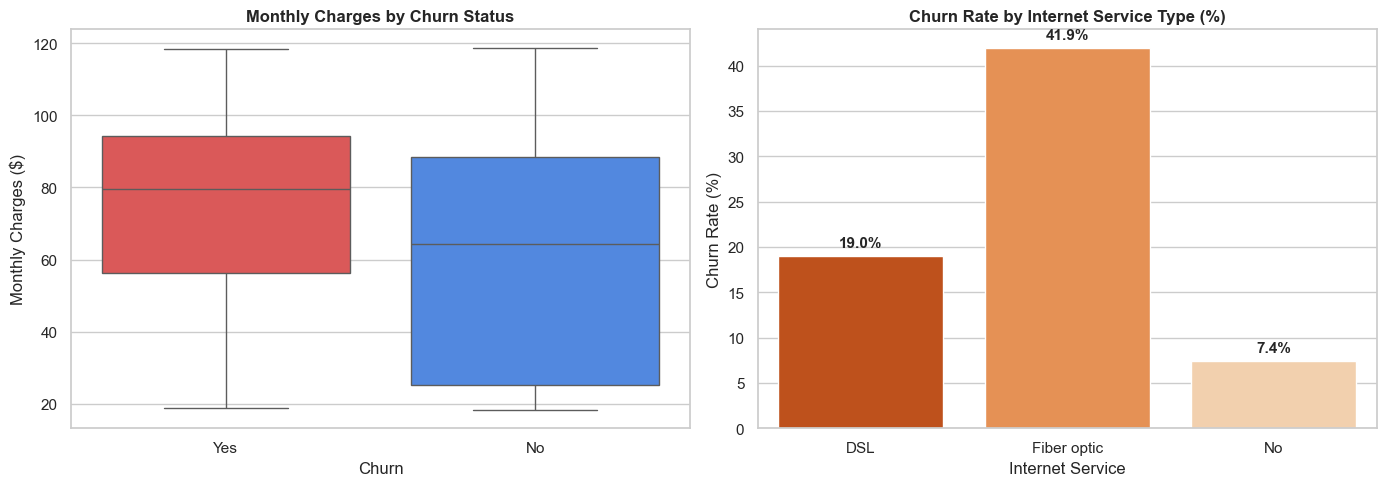

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Boxplot of Monthly Charges vs Churn
sns.boxplot(data=df, x="Churn", y="Monthly Charges", palette={"No": "#3B82F6", "Yes": "#EF4444"}, ax=axes[0])
axes[0].set_title("Monthly Charges by Churn Status", fontweight='bold')
axes[0].set_ylabel("Monthly Charges ($)")

# Internet Service vs Churn Rate
internet_churn = df.groupby("Internet Service")["Churn"].apply(lambda s: (s == "Yes").mean() * 100).reset_index()
sns.barplot(data=internet_churn, x="Internet Service", y="Churn", palette="Oranges_r", ax=axes[1])
axes[1].set_title("Churn Rate by Internet Service Type (%)", fontweight='bold')
axes[1].set_ylabel("Churn Rate (%)")
for p in axes[1].patches:
    axes[1].annotate(f"{p.get_height():.1f}%", (p.get_x() + p.get_width() / 2., p.get_height() + 1), ha='center', fontweight='bold')

plt.tight_layout()
plt.show()


> **💡 Key Finding:**
> - Churned customers pay a substantially **higher median monthly fee (~$80)** than retained customers (~$64).
> - **Fiber Optic** customers display an alarmingly high churn rate (**41.9%**), compared to DSL (19.0%) and No Internet (7.4%). This suggests potential service dissatisfaction, pricing friction, or competitive fiber alternatives.



### 6.4 Influence of Value-Added Services (Tech Support, Online Security) & Payment Method


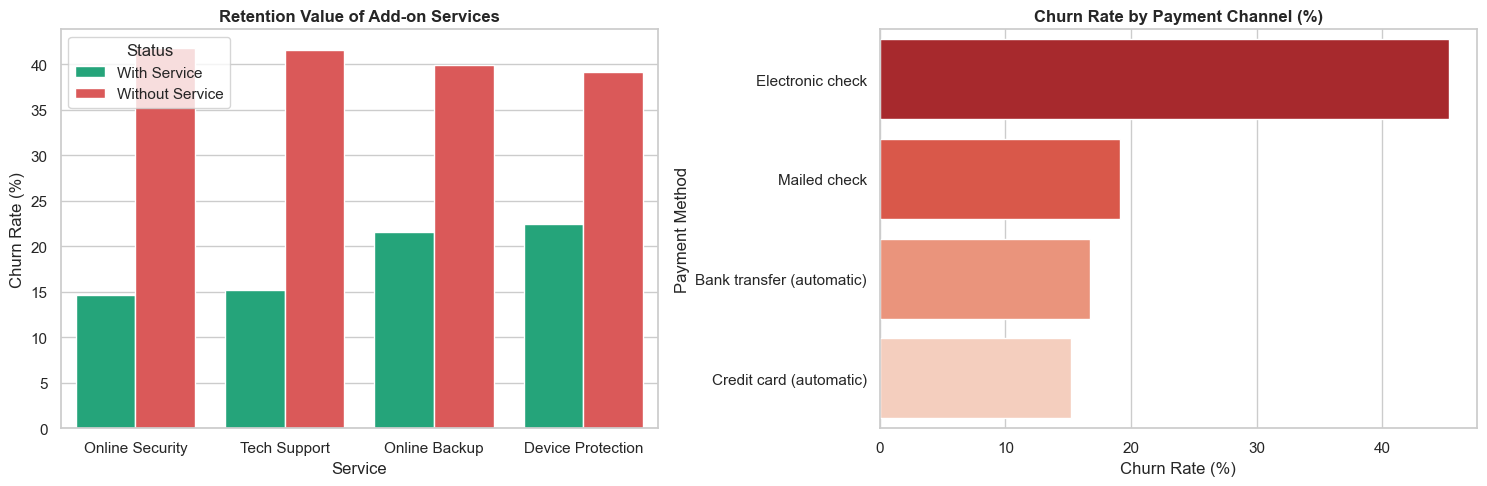

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Services comparison
services = ["Online Security", "Tech Support", "Online Backup", "Device Protection"]
churn_rates = []
for s in services:
    val = df.groupby(s)["Churn"].apply(lambda x: (x == "Yes").mean() * 100).to_dict()
    churn_rates.append({"Service": s, "With Service": val.get("Yes", 0), "Without Service": val.get("No", 0)})

df_serv = pd.DataFrame(churn_rates).melt(id_vars="Service", var_name="Status", value_name="Churn Rate (%)")
sns.barplot(data=df_serv, x="Service", y="Churn Rate (%)", hue="Status", palette=["#10B981", "#EF4444"], ax=axes[0])
axes[0].set_title("Retention Value of Add-on Services", fontweight='bold')
axes[0].set_ylabel("Churn Rate (%)")

# Payment Method Churn
pay_churn = df.groupby("Payment Method")["Churn"].apply(lambda s: (s == "Yes").mean() * 100).sort_values(ascending=False).reset_index()
sns.barplot(data=pay_churn, y="Payment Method", x="Churn", palette="Reds_r", ax=axes[1])
axes[1].set_title("Churn Rate by Payment Channel (%)", fontweight='bold')
axes[1].set_xlabel("Churn Rate (%)")

plt.tight_layout()
plt.show()


> **💡 Key Finding:**
> - Customers lacking **Tech Support** or **Online Security** churn at over **40%**, whereas customers who subscribe to them churn at less than **16%**. These add-ons act as major **stickiness anchors**.
> - **Electronic Check** payment channel has by far the highest churn rate (~45%), whereas automated bank transfer and credit card payments exhibit less than 18% churn.



# 7. 🌐 Multivariate Analysis & Feature Correlation

We now examine interactions between multiple features and inspect the numerical correlation heatmap.



### 7.1 Contract, Monthly Spend, and Tenure Joint Impact


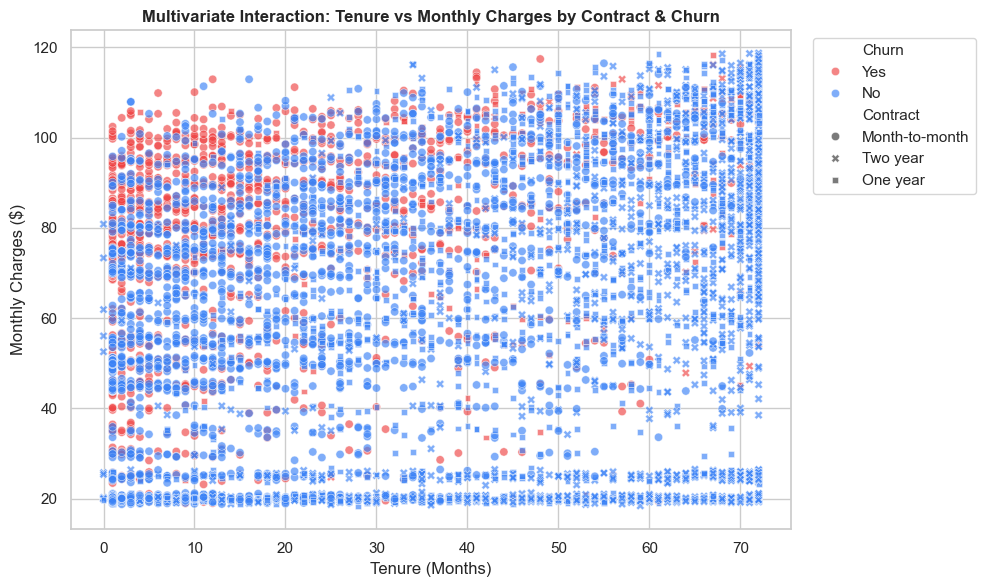

In [31]:
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=df,
    x="Tenure Months",
    y="Monthly Charges",
    hue="Churn",
    style="Contract",
    alpha=0.65,
    palette={"No": "#3B82F6", "Yes": "#EF4444"}
)
plt.title("Multivariate Interaction: Tenure vs Monthly Charges by Contract & Churn", fontweight='bold')
plt.xlabel("Tenure (Months)")
plt.ylabel("Monthly Charges ($)")
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()


> **💡 Key Finding:**
> - The cluster of churned customers (red points) is overwhelmingly concentrated in the **top-left quadrant**: **Low Tenure (< 20 months) + High Monthly Charges (> $70) + Month-to-month contracts**.
> - Once customers pass the 30-month mark and transition into annual contracts, even high monthly bills rarely result in churn.



### 7.2 Correlation Matrix (Cleaned Modeling Features)


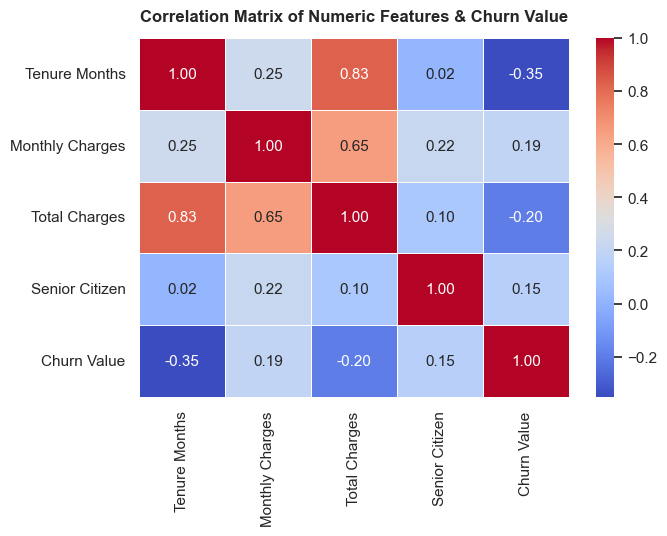

In [32]:
corr_cols = ["Tenure Months", "Monthly Charges", "Total Charges"]

if "Senior Citizen" in df.columns:
    if df["Senior Citizen"].dtype == "object":
        df["Senior Citizen"] = df["Senior Citizen"].map({"Yes": 1, "No": 0})
    corr_cols.append("Senior Citizen")

if "Churn Value" in df.columns:
    corr_cols.append("Churn Value")
elif "Churn" in df.columns:
    df["Churn Value"] = df["Churn"].map({"Yes": 1, "No": 0})
    corr_cols.append("Churn Value")
corr_matrix = df[corr_cols].apply(pd.to_numeric, errors='coerce').corr()

plt.figure(figsize=(7, 5.5))
sns.heatmap(corr_matrix, annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5, cbar=True)
plt.title("Correlation Matrix of Numeric Features & Churn Value", fontweight='bold', pad=12)
plt.tight_layout()
plt.show()

> **💡 Correlation Summary:**
> - `Churn Value` correlates negatively with `Tenure Months` ($-0.35$).
> - `Churn Value` correlates positively with `Monthly Charges` ($+0.19$).
> - `Total Charges` has strong collinearity with `Tenure Months` ($+0.83$), reinforcing why tenure is the primary temporal anchor.



# 8. 🚀 Bridge to MLOps Simulator & Feature Drift Monitoring

## 🎯 How this EDA Directly Connects to `simulate_retraining.py`:

The core objective of our production pipeline in this graduation project is not just a one-off static classifier, but a **continuous retraining simulator** monitoring data drift across 8 weekly batches (`data/live/features/week_1_features.csv` to `week_8_features.csv`):

| Key Feature Identified in EDA | Business Mechanism | Expected Drift Impact in MLOps Simulator |
| :--- | :--- | :--- |
| **`Contract` (Month-to-month)** | Primary churn hazard (42.7% churn rate) | If a marketing campaign increases month-to-month users, feature distribution shifts $\rightarrow$ triggers **KS / PSI Drift Warning**. |
| **`Tenure Months`** | New cohort vulnerability (<12 months = 47% churn) | A seasonal surge of new customers shifts the tenure median downwards $\rightarrow$ triggers retraining to adjust class decision boundaries. |
| **`Payment Method` (Electronic Check)** | High attrition payment channel (45% churn) | Channel migration directly changes model confidence and feature importance weights. |
| **`Internet Service_Fiber optic`** | High-cost tier friction (41.9% churn) | Pricing changes will induce distribution drift in both `Monthly Charges` and fiber one-hot indicators. |
| **`Tech Support` & `Online Security`** | Defensive retention anchors (<16% churn) | Changes in add-on bundle promotions alter retention probabilities. |

### 🔄 The Simulator Workflow:
1. `data/reference/X_reference.csv`: Represents the baseline reference distribution established by this EDA.
2. `simulate_retraining.py`: Iteratively ingests incoming weekly data (`data/live/features/`), calculates drift metrics (`drift_metrics.csv`), and evaluates performance degradation.
3. **Automated Trigger:** When drift surpasses predefined statistical thresholds (seen in `week_3` and `week_7`), the simulator triggers automatic model retraining and logs updated metrics in `data/retraining/`.

---

## 🏁 Conclusion & Recommendations:
1. **Target New Onboarding:** Launch proactive loyalty and onboarding incentives in months $1-6$ to overcome the high early-tenure drop-off.
2. **Contract Migration Campaigns:** Offer modest monthly discounts to migrate Month-to-Month subscribers into 1-year or 2-year commitments.
3. **Fiber Service & Support Bundling:** Bundle free Tech Support and Online Security with Fiber Optic plans to counter the elevated 42% fiber churn rate.
4. **Deploy Drift Alarms:** Monitor the top 5 driver features (`Contract`, `Tenure`, `MonthlyCharges`, `InternetService`, `TechSupport`) as priority sentinel features in the MLOps monitoring dashboard.

